In [1]:
library(ggplot2)

In [9]:
df = read.table("kmer_freq_allstrains.Rin", sep = '\t', header = TRUE)
df$strain <- factor(df$strain, 
    levels=c('12B1','NIES1812','PK2298B4',
             'CC2192B4','CC2192B5','CC2192C1','CC2192D2','CC2192D3','CCMP3037',
             'RCC3703','CCMP2941',
             '8020','8027',
             '12A1','12A1-SC1','12A1-SC2','12A1-SC3',
             '13A5','ARC66','ARC81','ARC82','ARC83','ARC84',
             'PK2297D4','PK2298C6','PK2299B3','PK2300D3',
             'UTEX2797','UTEX2797-SC1','UTEX2797-SC2','UTEX2797-SC3','UTEX2797-SC4',
             'UTEX2827'))       
sub.df <- df[!grepl("-SC\\d+$", df$strain), ]
head(sub.df)

,cov,freq,strain
,<int>,<int>,<fct>
1,11,818679,UTEX2797
2,12,817873,UTEX2797
3,13,825507,UTEX2797
4,14,844088,UTEX2797
5,15,861957,UTEX2797
6,16,877229,UTEX2797


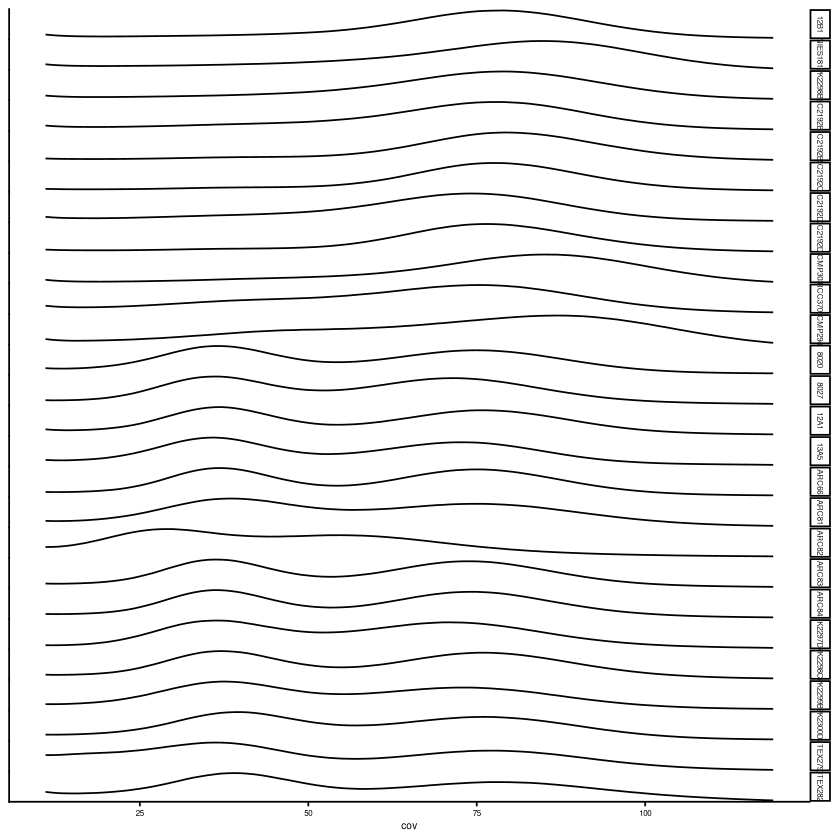

In [10]:
gg = ggplot(data=sub.df, aes(x=cov, y=freq))
gg = gg + geom_line()
gg = gg + facet_grid(strain ~ ., scales = "free_y")
gg = gg + theme_classic()
# gg = gg + labs(x='K-mer coverage', y=NULL, color="Prymnesin type") 
# gg = gg + scale_color_manual(values=c("#d95f02", "#7570b3", "#1b9e77"))
gg = gg + theme(legend.position="none")
gg = gg + theme(axis.title.y=element_blank(), axis.text.y=element_blank(), axis.ticks.y=element_blank())
gg = gg + theme(text = element_text(size=6))
gg = gg + theme(panel.spacing = unit(.01, "cm"))
gg

In [11]:
ggsave('kmer_plots.pdf', device = "pdf", width = 1, height = 6.5, units = "in")

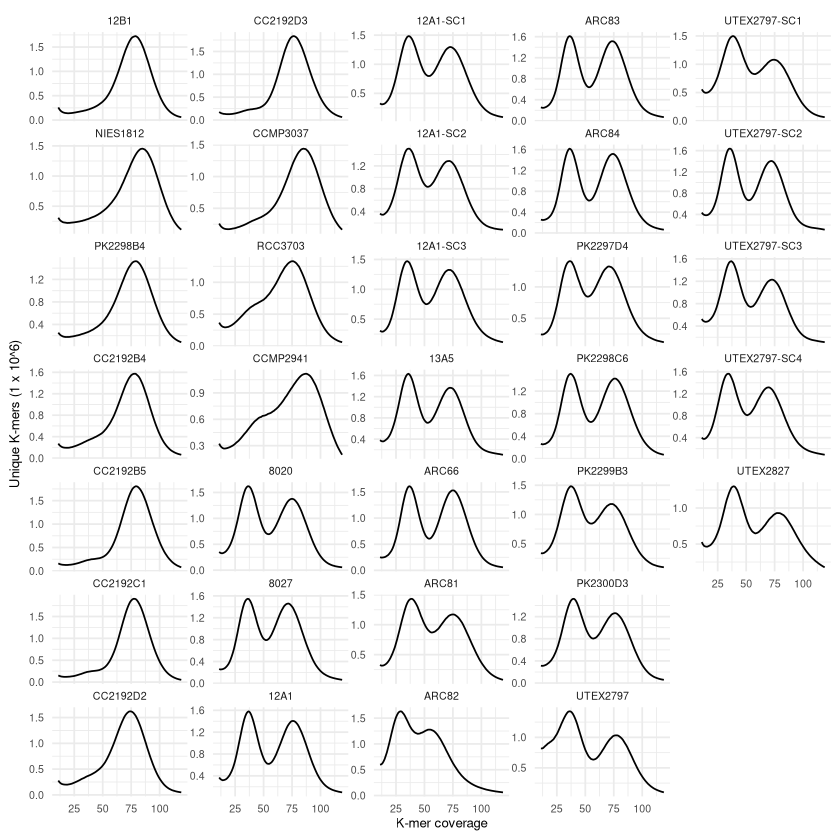

In [7]:
gg = ggplot(data=df, aes(x=cov, y=freq/1000000))
gg = gg + geom_line()
gg = gg + facet_wrap( ~ strain, scales = "free_y", ncol = 5, dir = "v")
gg = gg + theme_minimal()
gg = gg + labs(x='K-mer coverage', y='Unique K-mers (1 x 10^6)') 
# gg = gg + scale_color_manual(values=c("#d95f02", "#7570b3", "#1b9e77"))
gg = gg + theme(legend.position="none")
#gg = gg + theme(axis.title.y=element_blank(), axis.text.y=element_blank(), axis.ticks.y=element_blank())
gg = gg + theme(text = element_text(size=8))
gg = gg + theme(panel.spacing = unit(.01, "cm"))
gg

In [8]:
ggsave('kmer_plots_supplemental.pdf', device = "pdf", width = 6, height = 6, units = "in")